# Lab 3: Linear Regression
**Dataset:** Auto MPG — fuel efficiency of real cars (1970–1982)
**Goal:** Predict a car's **miles per gallon (mpg)** from its weight and other specifications, using linear regression built from scratch.

## 1. Roadmap
| Step | What we do | Why |
|---|---|---|
| A | **Simple linear regression** (1 feature: weight), closed-form formulas | The core idea: fit the best straight line |
| B | **Gradient descent** on the same problem | How a computer *learns* the line step by step |
| C | **Multiple linear regression** (many features), normal equation | Use more information to predict better |
| D | Diagnostics, comparison, scikit-learn cross-check | Check that the model is trustworthy |

## 2. Core Concepts
| Concept | Formula | Meaning |
|---|---|---|
| **Model** | ŷ = b₀ + b₁x | Straight line. b₀ = intercept, b₁ = slope (change in y per unit of x) |
| **Residual** | eᵢ = yᵢ − ŷᵢ | Error of one prediction |
| **Least squares** | minimise SSE = Σ eᵢ² | The best line has the smallest total squared error |
| **Slope** | b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² | Closed-form answer for 1 feature |
| **Intercept** | b₀ = ȳ − b₁ x̄ | The line always passes through (x̄, ȳ) |
| **Normal equation** | β = (XᵀX)⁻¹ Xᵀ y | Closed-form answer for many features |
| **Gradient descent** | b ← b − α · ∂J/∂b, J = (1/2m) Σ eᵢ² | Repeatedly step downhill on the error surface (α = learning rate) |
| **MSE / RMSE / MAE** | mean of e² / √MSE / mean of \|e\| | Error size (RMSE and MAE are in mpg) |
| **R²** | 1 − SSE / SST | Share of the variation in y explained by the model (1 = perfect, 0 = same as predicting the mean) |
| **Adjusted R²** | 1 − (1 − R²)(n − 1)/(n − p − 1) | R² corrected for the number of features p |

**Assumptions (LINE):** Linear relationship, Independent errors, Normally distributed residuals, Equal variance of residuals.

## 3. Dataset: Auto MPG
- 398 cars, target = `mpg` (miles per gallon)

| Attribute | Type | Meaning |
|---|---|---|
| cylinders | numeric | Number of engine cylinders |
| displacement | numeric | Engine size (cubic inches) |
| horsepower | numeric (6 missing) | Engine power |
| weight | numeric | Car weight (lbs) |
| acceleration | numeric | Seconds to reach 60 mph |
| model_year | numeric | Year (70 = 1970) |
| origin | categorical | usa / japan / europe |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

navy, blue, light = "#1F3A5F", "#3E7CB1", "#A9C7E8"

raw = pd.read_csv("data/auto_mpg.csv")
print("Rows:", len(raw), "| Missing horsepower:", int(raw.horsepower.isna().sum()))

df = raw.dropna(subset=["horsepower"]).reset_index(drop=True)      # only 6 rows removed
df["weight_k"] = df["weight"] / 1000                                 # weight in 1000 lbs (easier numbers)
print("Rows used:", len(df))
df[["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year", "origin"]].describe().round(2)

Rows: 398 | Missing horsepower: 6
Rows used: 392


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,392.00,392.00,392.00,392.00,392.00,392.00,392.00
mean,23.45,5.47,194.41,104.47,2977.58,15.54,75.98
std,7.81,1.71,104.64,38.49,849.40,2.76,3.68
min,9.00,3.00,68.00,46.00,1613.00,8.00,70.00
25%,17.00,4.00,105.00,75.00,2225.25,13.78,73.00
50%,22.75,4.00,151.00,93.50,2803.50,15.50,76.00
75%,29.00,8.00,275.75,126.00,3614.75,17.02,79.00
max,46.60,8.00,455.00,230.00,5140.00,24.80,82.00


Correlation with mpg:
weight         -0.832
displacement   -0.805
cylinders      -0.778
horsepower     -0.778
acceleration    0.423
model_year      0.581
Name: mpg, dtype: float64


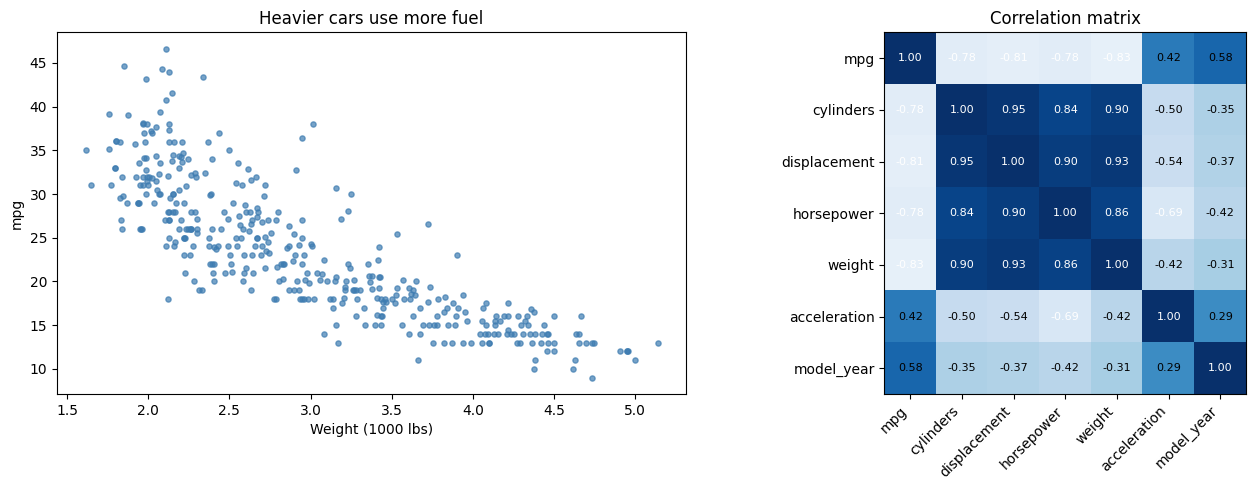

In [2]:
num_cols = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
corr = df[num_cols].corr()
print("Correlation with mpg:")
print(corr["mpg"].drop("mpg").round(3).sort_values())

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(df.weight_k, df.mpg, s=14, color=blue, alpha=0.7)
ax[0].set_xlabel("Weight (1000 lbs)"); ax[0].set_ylabel("mpg"); ax[0].set_title("Heavier cars use more fuel")
im = ax[1].imshow(corr, cmap="Blues", vmin=-1, vmax=1)
ax[1].set_xticks(range(len(num_cols))); ax[1].set_xticklabels(num_cols, rotation=45, ha="right")
ax[1].set_yticks(range(len(num_cols))); ax[1].set_yticklabels(num_cols)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax[1].text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8,
                   color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

## 4. Manual Calculation (same steps you do on paper)
Using the **first 8 cars** in the dataset (real rows), predict `mpg` from `weight` (in 1000 lbs).

In [3]:
m8 = df.head(8)
x, y = m8.weight_k.values, m8.mpg.values
xb, yb = x.mean(), y.mean()
print(f"x-bar = {xb:.5f}   y-bar = {yb:.3f}\n")
print(f"{'car':28s}{'x':>7s}{'y':>5s}{'x-xbar':>9s}{'y-ybar':>9s}{'(dx)(dy)':>10s}{'(dx)^2':>9s}")
for name, xi, yi in zip(m8.name, x, y):
    dx, dy = xi - xb, yi - yb
    print(f"{name:28s}{xi:7.3f}{yi:5.0f}{dx:9.4f}{dy:9.3f}{dx * dy:10.4f}{dx * dx:9.4f}")
Sxy, Sxx = ((x - xb) * (y - yb)).sum(), ((x - xb) ** 2).sum()
b1 = Sxy / Sxx; b0 = yb - b1 * xb
print(f"\nSxy = {Sxy:.4f}   Sxx = {Sxx:.4f}")
print(f"b1 = Sxy / Sxx = {b1:.4f}")
print(f"b0 = y-bar - b1 * x-bar = {b0:.4f}")
yhat = b0 + b1 * x
SSE, SST = ((y - yhat) ** 2).sum(), ((y - yb) ** 2).sum()
print(f"\nEquation: mpg = {b0:.3f} + ({b1:.3f}) * weight_k")
print(f"SSE = {SSE:.4f}   SST = {SST:.4f}   R2 = 1 - SSE/SST = {1 - SSE / SST:.4f}")
print(f"RMSE = {np.sqrt(SSE / 8):.4f}   MAE = {np.abs(y - yhat).mean():.4f}")
print(f"Prediction for a 3000 lb car: {b0 + b1 * 3.0:.2f} mpg")

x-bar = 3.81525   y-bar = 15.875

car                               x    y   x-xbar   y-ybar  (dx)(dy)   (dx)^2
chevrolet chevelle malibu     3.504   18  -0.3112    2.125   -0.6614   0.0969
buick skylark 320             3.693   15  -0.1222   -0.875    0.1070   0.0149
plymouth satellite            3.436   18  -0.3792    2.125   -0.8059   0.1438
amc rebel sst                 3.433   16  -0.3822    0.125   -0.0478   0.1461
ford torino                   3.449   17  -0.3662    1.125   -0.4120   0.1341
ford galaxie 500              4.341   15   0.5258   -0.875   -0.4600   0.2764
chevrolet impala              4.354   14   0.5388   -1.875   -1.0102   0.2903
plymouth fury iii             4.312   14   0.4968   -1.875   -0.9314   0.2468

Sxy = -4.2218   Sxx = 1.3493
b1 = Sxy / Sxx = -3.1288
b0 = y-bar - b1 * x-bar = 27.8120

Equation: mpg = 27.812 + (-3.129) * weight_k
SSE = 5.6661   SST = 18.8750   R2 = 1 - SSE/SST = 0.6998
RMSE = 0.8416   MAE = 0.7149
Prediction for a 3000 lb car: 18.43 mpg


**Why is the 8-car slope (-3.13) so different from the slope on the full data (-7.90)?** These 8 cars are all big American cars from 1970 with a narrow weight range (3.4 to 4.4 tons-of-1000-lbs), so their slope is unstable. A small, narrow sample can mislead; the full data gives a more reliable line.

In [4]:
# 80/20 split used for all models
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=0.2, random_state=42)
tr = df.iloc[train_idx].reset_index(drop=True)
te = df.iloc[test_idx].reset_index(drop=True)
ytr, yte = tr.mpg.values, te.mpg.values
print("Train:", len(tr), "| Test:", len(te))

def metrics(y, yh, p=None):
    e = y - yh
    sse, sst, n = (e ** 2).sum(), ((y - y.mean()) ** 2).sum(), len(y)
    out = {"MSE": sse / n, "RMSE": np.sqrt(sse / n), "MAE": np.abs(e).mean(), "R2": 1 - sse / sst}
    if p is not None:
        out["Adj R2"] = 1 - (1 - out["R2"]) * (n - 1) / (n - p - 1)
    return out

Train: 313 | Test: 79


# Part A — Simple Linear Regression (closed form)
One feature (`weight_k`), two unknowns (b₀, b₁). The least-squares formulas give the exact best line, no iteration needed.

mpg = 47.201 + (-7.904) * weight_k
-> every extra 1000 lbs changes mpg by -7.90

          Train     Test
MSE     19.0451  17.6934
RMSE     4.3641   4.2064
MAE      3.2855   3.4641
R2       0.6982   0.6533
Adj R2   0.6972   0.6488


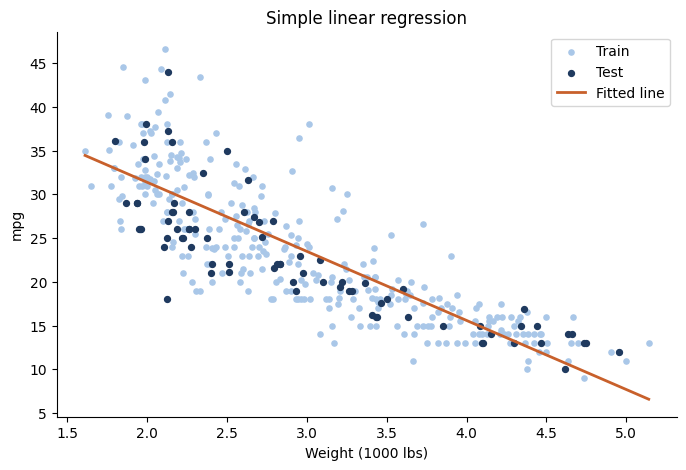

In [5]:
def fit_simple(x, y):
    xb, yb = x.mean(), y.mean()
    b1 = ((x - xb) * (y - yb)).sum() / ((x - xb) ** 2).sum()
    return yb - b1 * xb, b1

b0, b1 = fit_simple(tr.weight_k.values, ytr)
print(f"mpg = {b0:.3f} + ({b1:.3f}) * weight_k")
print(f"-> every extra 1000 lbs changes mpg by {b1:.2f}\n")

pred_tr, pred_te = b0 + b1 * tr.weight_k.values, b0 + b1 * te.weight_k.values
simple_tr, simple_te = metrics(ytr, pred_tr, 1), metrics(yte, pred_te, 1)
print(pd.DataFrame({"Train": simple_tr, "Test": simple_te}).round(4))

xs = np.linspace(df.weight_k.min(), df.weight_k.max(), 100)
plt.figure(figsize=(8, 5))
plt.scatter(tr.weight_k, ytr, s=14, color=light, label="Train")
plt.scatter(te.weight_k, yte, s=18, color=navy, label="Test")
plt.plot(xs, b0 + b1 * xs, color="#C8602B", lw=2, label="Fitted line")
plt.xlabel("Weight (1000 lbs)"); plt.ylabel("mpg"); plt.legend(); plt.title("Simple linear regression")
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

# Part B — Gradient Descent
Instead of the formula, start with b₀ = b₁ = 0 and repeat: compute the error → compute the slope of the cost → take a small step downhill. We **standardise x** first so both parameters move at a similar speed, then convert the result back.

Gradient descent : mpg = 47.2005 + (-7.9036) * weight_k
Closed form      : mpg = 47.2005 + (-7.9036) * weight_k
Final cost: 9.5226


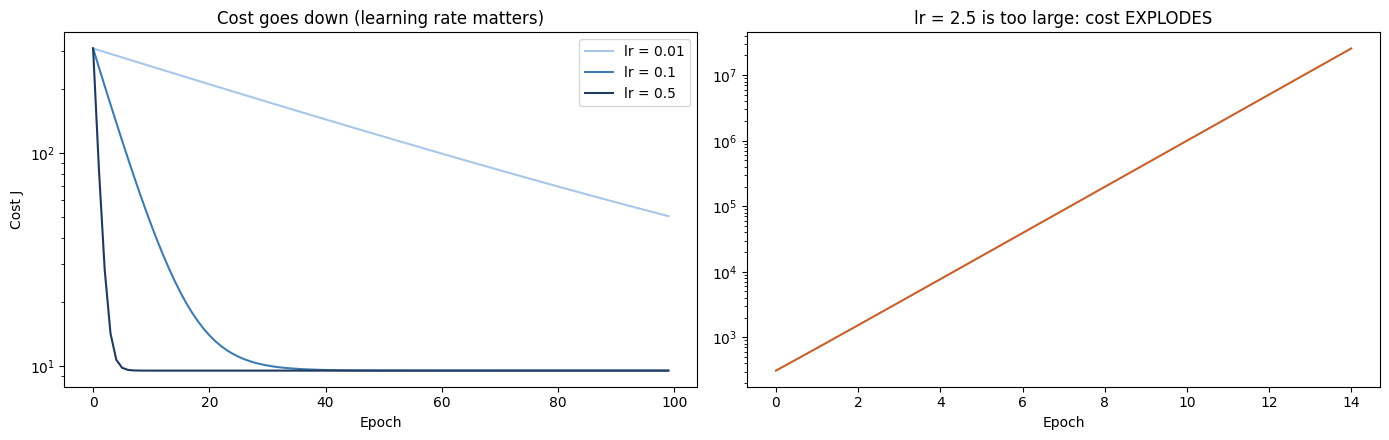

Cost after 15 epochs with lr = 2.5: 2.561e+07


In [6]:
def gradient_descent(x, y, lr=0.1, epochs=200):
    mu, sd = x.mean(), x.std()
    z = (x - mu) / sd                                   # standardised feature
    w0 = w1 = 0.0
    history = []
    for _ in range(epochs):
        err = (w0 + w1 * z) - y
        history.append((err ** 2).mean() / 2)           # cost J = (1/2m) * sum(err^2)
        w0 -= lr * err.mean()                           # dJ/dw0
        w1 -= lr * (err * z).mean()                     # dJ/dw1
    return w0 - w1 * mu / sd, w1 / sd, history          # back to the original scale

x_tr = tr.weight_k.values
gd_b0, gd_b1, hist = gradient_descent(x_tr, ytr, lr=0.1, epochs=200)
print(f"Gradient descent : mpg = {gd_b0:.4f} + ({gd_b1:.4f}) * weight_k")
print(f"Closed form      : mpg = {b0:.4f} + ({b1:.4f}) * weight_k")
print("Final cost:", round(hist[-1], 4))

with np.errstate(all="ignore"):
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for lr, col in [(0.01, light), (0.1, blue), (0.5, navy)]:
        _, _, h = gradient_descent(x_tr, ytr, lr=lr, epochs=100)
        ax[0].plot(h, color=col, label=f"lr = {lr}")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cost J"); ax[0].set_title("Cost goes down (learning rate matters)"); ax[0].legend()
    ax[0].set_yscale("log")
    _, _, h_bad = gradient_descent(x_tr, ytr, lr=2.5, epochs=15)
    ax[1].plot(h_bad, color="#C8602B"); ax[1].set_yscale("log")
    ax[1].set_xlabel("Epoch"); ax[1].set_title("lr = 2.5 is too large: cost EXPLODES")
    plt.tight_layout(); plt.show()
print("Cost after 15 epochs with lr = 2.5:", f"{h_bad[-1]:.3e}")

**What to notice:** gradient descent ends at (almost exactly) the same line as the formula. A tiny learning rate is slow, a good one converges quickly, and a too-large one makes the cost explode. For simple regression the formula is enough, but gradient descent is the method that scales to huge data and to other models (logistic regression, neural networks).

# Part C — Multiple Linear Regression
Now use **all** specifications: ŷ = b₀ + b₁x₁ + b₂x₂ + … + b₈x₈. The normal equation β = (XᵀX)⁻¹Xᵀy gives all coefficients at once. The categorical `origin` becomes 0/1 columns (`europe` is the reference group).

In [7]:
feat_cols = ["cylinders", "displacement", "horsepower", "weight_k", "acceleration", "model_year"]

def design(d, quad=False):
    X = d[feat_cols].copy()
    X["origin_japan"] = (d.origin == "japan").astype(int)
    X["origin_usa"] = (d.origin == "usa").astype(int)
    if quad:
        X["weight_k_sq"] = d.weight_k ** 2
    return X

def fit_normal(X, y):
    A = np.column_stack([np.ones(len(X)), X.values.astype(float)])
    return np.linalg.solve(A.T @ A, A.T @ y)             # beta = (A'A)^-1 A'y

def predict_lin(beta, X):
    return beta[0] + X.values.astype(float) @ beta[1:]

Xtr, Xte = design(tr), design(te)
beta = fit_normal(Xtr, ytr)

coef = pd.DataFrame({"Feature": ["intercept"] + list(Xtr.columns), "Coefficient": beta})
coef["Std. coefficient"] = [np.nan] + [b * Xtr[c].std() / ytr.std() for b, c in zip(beta[1:], Xtr.columns)]
print(coef.round(4).to_string(index=False))

mult_tr, mult_te = metrics(ytr, predict_lin(beta, Xtr), Xtr.shape[1]), metrics(yte, predict_lin(beta, Xte), Xtr.shape[1])
print("\n" + pd.DataFrame({"Train": mult_tr, "Test": mult_te}).round(4).to_string())

     Feature  Coefficient  Std. coefficient
   intercept     -16.4564               NaN
   cylinders      -0.3421           -0.0732
displacement       0.0192            0.2509
  horsepower      -0.0216           -0.1042
    weight_k      -6.4227           -0.6801
acceleration       0.0422            0.0150
  model_year       0.7972            0.3643
origin_japan       0.3305            0.0167
  origin_usa      -2.8755           -0.1735

          Train     Test
MSE     10.8098  10.6023
RMSE     3.2878   3.2561
MAE      2.5446   2.4620
R2       0.8287   0.7923
Adj R2   0.8242   0.7685


**How to read the table**
- **Coefficient** = change in mpg for +1 unit of that feature, *holding the other features fixed*
- **Std. coefficient** puts all features on the same scale, so you can compare their importance (bigger absolute value = stronger effect)

In [8]:
# Multicollinearity check: features that carry almost the same information
cm = Xtr[feat_cols].corr()
pairs = [(a, b, cm.loc[a, b]) for i, a in enumerate(feat_cols) for b in feat_cols[i + 1:] if abs(cm.loc[a, b]) > 0.8]
print("Feature pairs with |correlation| > 0.8:")
for a, b, r in sorted(pairs, key=lambda t: -abs(t[2])):
    print(f"  {a:13s} - {b:13s}: {r:.3f}")

Feature pairs with |correlation| > 0.8:
  cylinders     - displacement : 0.953
  displacement  - weight_k     : 0.927
  cylinders     - weight_k     : 0.893
  displacement  - horsepower   : 0.893
  horsepower    - weight_k     : 0.856
  cylinders     - horsepower   : 0.844


In [9]:
# Cross-check our scratch models against scikit-learn
from sklearn.linear_model import LinearRegression

sk_simple = LinearRegression().fit(tr[["weight_k"]], ytr)
sk_multi = LinearRegression().fit(Xtr, ytr)
print("Simple   : scratch == sklearn ->", np.allclose([b0, b1], [sk_simple.intercept_, sk_simple.coef_[0]]))
print("Multiple : scratch == sklearn ->", np.allclose(beta, np.r_[sk_multi.intercept_, sk_multi.coef_]))
print("Test R2 (sklearn multiple):", round(sk_multi.score(Xte, yte), 4))

Simple   : scratch == sklearn -> True
Multiple : scratch == sklearn -> True
Test R2 (sklearn multiple): 0.7923


# Part D — Diagnostics and Comparison
A good R² is not enough. We also check the LINE assumptions with **residual plots**: residuals should scatter randomly around 0 with no pattern.

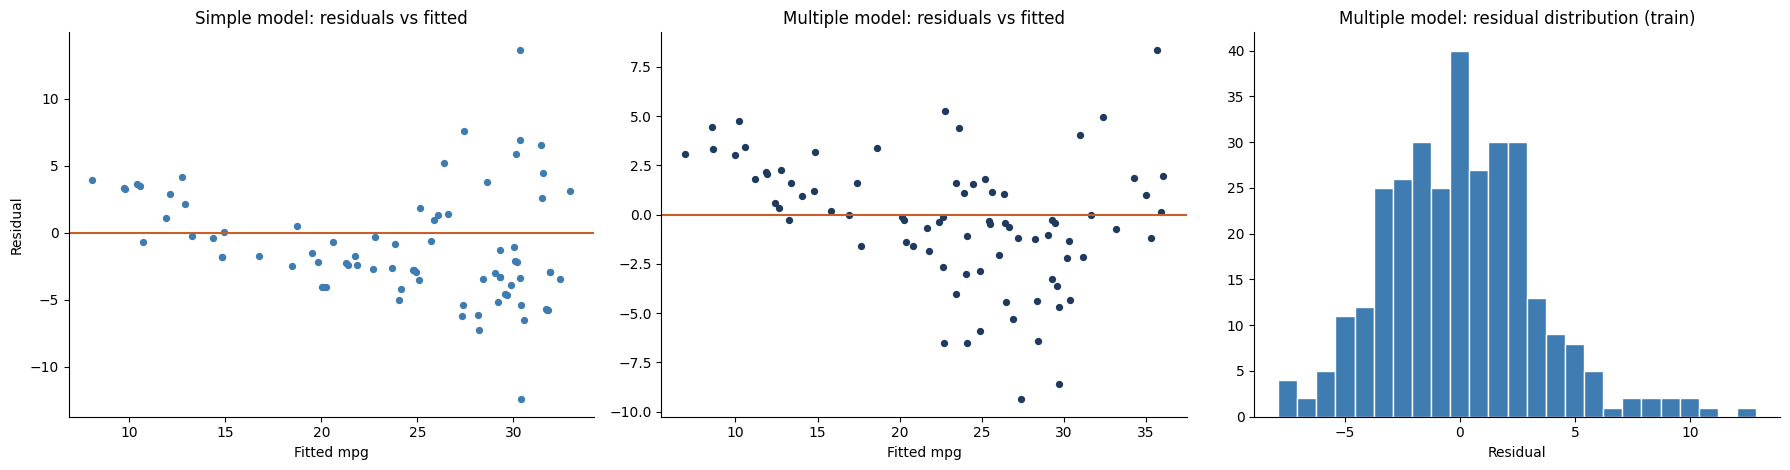

Mean residual (train): -0.0 (always ~0 with an intercept)


In [10]:
fitted_te = predict_lin(beta, Xte); res_te = yte - fitted_te
res_tr = ytr - predict_lin(beta, Xtr)
res_simple = yte - pred_te

fig, ax = plt.subplots(1, 3, figsize=(18, 4.8))
ax[0].scatter(pred_te, res_simple, s=18, color=blue)
ax[0].axhline(0, color="#C8602B"); ax[0].set_title("Simple model: residuals vs fitted")
ax[0].set_xlabel("Fitted mpg"); ax[0].set_ylabel("Residual")
ax[1].scatter(fitted_te, res_te, s=18, color=navy)
ax[1].axhline(0, color="#C8602B"); ax[1].set_title("Multiple model: residuals vs fitted")
ax[1].set_xlabel("Fitted mpg")
ax[2].hist(res_tr, bins=25, color=blue, edgecolor="white")
ax[2].set_title("Multiple model: residual distribution (train)"); ax[2].set_xlabel("Residual")
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("Mean residual (train):", round(res_tr.mean(), 6), "(always ~0 with an intercept)")

**Reading the residual plots (simple model):** the residuals form a curve (positive for very low and very high fitted values, negative in the middle), and their spread gets wider for high-mpg cars. So the relation between weight and mpg is not a perfectly straight line, and the error size is not constant (unequal variance). The multiple model still shows a mild curve and a right-skewed residual histogram. Linear regression is *linear in the coefficients*, so we can reduce the curvature by adding a squared weight column (a log transform of mpg is another common fix).

                     Model  Test R2  Test RMSE  Test MAE
Baseline: predict the mean  -0.0114     7.1847    5.8810
           Simple (weight)   0.6533     4.2064    3.4641
         Simple + weight^2   0.6730     4.0852    3.1383
     Multiple (8 features)   0.7923     3.2561    2.4620
       Multiple + weight^2   0.8238     2.9991    2.2518


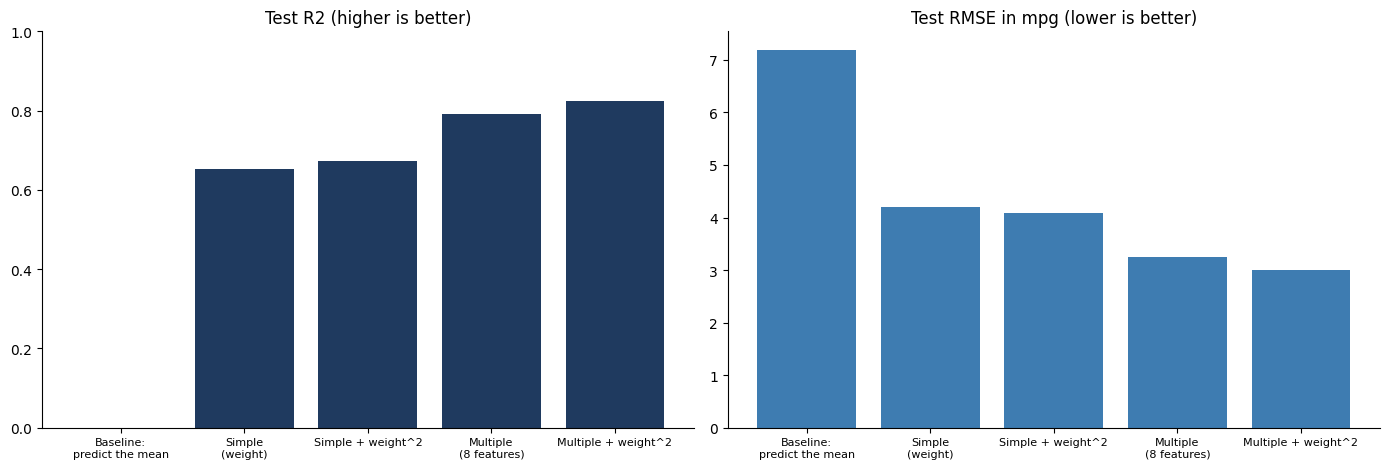

In [11]:
# Fix for curvature: add weight^2 as an extra column (still a linear regression!)
Xq_tr, Xq_te = design(tr, quad=True), design(te, quad=True)
beta_q = fit_normal(Xq_tr, ytr)
multq_te = metrics(yte, predict_lin(beta_q, Xq_te), Xq_tr.shape[1])

simple_q = LinearRegression().fit(tr[["weight_k"]].assign(w2=tr.weight_k ** 2), ytr)
simpleq_te = metrics(yte, simple_q.predict(te[["weight_k"]].assign(w2=te.weight_k ** 2)), 2)

rows = [
    ("Baseline: predict the mean", metrics(yte, np.full(len(yte), ytr.mean())), None),
    ("Simple (weight)", simple_te, simple_tr),
    ("Simple + weight^2", simpleq_te, None),
    ("Multiple (8 features)", mult_te, mult_tr),
    ("Multiple + weight^2", multq_te, None),
]
table = pd.DataFrame([{"Model": n, "Test R2": t["R2"], "Test RMSE": t["RMSE"], "Test MAE": t["MAE"]} for n, t, _ in rows])
print(table.round(4).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
labels = [n.replace(" (", "\n(").replace(": ", ":\n") for n in table.Model]
ax[0].bar(labels, table["Test R2"], color=navy); ax[0].set_title("Test R2 (higher is better)"); ax[0].set_ylim(0, 1)
ax[1].bar(labels, table["Test RMSE"], color=blue); ax[1].set_title("Test RMSE in mpg (lower is better)")
for a in ax:
    a.tick_params(axis="x", labelsize=8); a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Final Conclusion
- **Simple model (weight only):** test R² = 0.653, RMSE = 4.21 mpg. On the full training data each extra 1000 lbs lowers mpg by about 7.9. Predicting the mean gives R² ≈ 0 and RMSE = 7.18, so weight alone already helps a lot.
- **Multiple model (8 features):** test R² = 0.792, RMSE = 3.26 mpg. More information cuts the typical error by about 1 mpg.
- **Adding weight²** improves it further (multiple: test R² 0.824, RMSE 3.00; simple: 0.673), because the weight-mpg relation is curved.
- **Gradient descent = formula:** both give mpg = 47.20 - 7.90 · weight_k. A learning rate of 2.5 makes the cost explode.
- **Validation:** our scratch models match scikit-learn exactly.
- **Multicollinearity:** displacement, cylinders, weight and horsepower are highly correlated (for example displacement-cylinders r = 0.953). Displacement even gets a *positive* coefficient although its correlation with mpg is negative (-0.805), so individual coefficients are unreliable. Weight (standardised coefficient -0.68) and model year (+0.36) are the strongest effects.
- **Limits:** residual plots show a curve and uneven spread, and results come from one 80/20 split (79 test cars), so small differences between models should not be over-interpreted.


## Viva Questions
| Question | Short answer |
|---|---|
| What does linear regression do? | Fits the line (or plane) that minimises the sum of squared errors between predictions and real values |
| Why *squared* errors? | Positive and negative errors do not cancel, big mistakes are punished more, and the maths gives a clean closed-form answer |
| What do b₀ and b₁ mean? | b₁ = change in y for +1 in x; b₀ = predicted y when x = 0 (may have no real meaning, e.g. a 0 lb car) |
| Normal equation vs gradient descent? | Normal equation gives the exact answer in one step but is slow for huge feature counts; gradient descent is iterative, scales better and is used for other models too |
| What is the learning rate? | Step size in gradient descent: too small = slow, too large = diverges |
| Why standardise features for gradient descent? | Features on different scales make the cost surface narrow and slow to descend |
| What does R² = 0.7 mean? | The model explains 70% of the variation in y |
| Why Adjusted R²? | Plain R² never decreases when you add features; adjusted R² penalises useless ones |
| What is multicollinearity? | Features that are highly correlated (weight, displacement, horsepower), which makes individual coefficients unstable, though predictions can still be good |
| What do residual plots tell us? | A pattern (like a curve) means the linear assumption is violated; a random cloud around 0 is good |
| Is it still "linear" with weight²? | Yes, linear regression means linear in the coefficients, not in the original features |